# U.S. butter cold-storage stocks: the seasonal cycle

Downloads the monthly USDA NASS *Cold Storage* butter stocks from the Quick Stats API, cleans and validates them,
and writes a print-ready, US-Letter, vector PDF (`figures/butter_cold_storage.pdf`) with a cover page and five charts.

Steps: **setup → fetch → clean → validate → charts → what the data shows → PDF export.**

## 1. Setup
The `REFRESH` flag forces a new download; otherwise the cached CSV in `data/raw/` is used so the notebook re-runs offline. The API key is read from `.env` via python-dotenv and is never printed or written anywhere.

In [1]:
REFRESH = False          # True = re-download from the NASS API even if a cached CSV exists

import os, json, textwrap, datetime as dt
from pathlib import Path
import numpy as np
import pandas as pd
import requests
from dotenv import load_dotenv
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.backends.backend_pdf import PdfPages
from matplotlib.colors import ListedColormap, Normalize
from matplotlib.cm import ScalarMappable
from IPython.display import Markdown, display

load_dotenv()            # reads NASS_API_KEY from .env (does not override an already-set env var)

BASE   = "https://quickstats.nass.usda.gov/api/"
RAW    = Path("data/raw");  RAW.mkdir(parents=True, exist_ok=True)
FIGS   = Path("figures");   FIGS.mkdir(exist_ok=True)
CSV    = RAW / "butter_cold_storage_raw.csv"
META   = RAW / "fetch_meta.json"

# Print / font settings (TrueType-embedded fonts, >= 8 pt, clean sans-serif)
plt.rcParams.update({
    "pdf.fonttype": 42, "ps.fonttype": 42,
    "font.family": "sans-serif",
    "font.sans-serif": ["Liberation Sans", "Arial", "Helvetica", "DejaVu Sans"],
    "font.size": 9, "axes.labelsize": 9, "xtick.labelsize": 8, "ytick.labelsize": 8,
    "axes.titlesize": 9, "axes.spines.top": False, "axes.spines.right": False,
    "figure.facecolor": "white", "savefig.facecolor": "white",
})
print("matplotlib", matplotlib.__version__, "| pandas", pd.__version__)

matplotlib 3.11.2 | pandas 3.0.0


## 2. Fetch
Parameter values are discovered with `get_param_values` rather than guessed, and `get_counts` is checked against the
50,000-record cap before the real pull. If any API call fails the notebook **stops with an error** (it does not
silently switch sources; the documented fallback would be the Cold Storage report files on USDA ESMIS).
The error message deliberately omits the request URL so the key cannot leak.

In [2]:
def api(endpoint, **params):
    key = os.environ.get("NASS_API_KEY")
    if not key:
        raise RuntimeError("NASS_API_KEY not found in .env / environment.")
    try:
        r = requests.get(BASE + endpoint + "/", params={"key": key, **params}, timeout=120)
        r.raise_for_status()
    except requests.RequestException as e:      # message intentionally excludes the URL (it contains the key)
        status = getattr(getattr(e, "response", None), "status_code", None)
        raise RuntimeError(f"NASS API call '{endpoint}' failed ({type(e).__name__}, HTTP status {status}). "
                           "Stopping; not switching sources. Fallback would be the Cold Storage files on USDA ESMIS.") from None
    return r

def param_values(param, **filters):
    return api("get_param_values", param=param, **filters).json()[param]

if CSV.exists() and META.exists() and not REFRESH:
    print("Using cached raw data (set REFRESH = True to re-download).")
    raw  = pd.read_csv(CSV, dtype=str, keep_default_na=False)
    meta = json.loads(META.read_text())
else:
    print("Querying the NASS Quick Stats API ...")
    butter_commodities = [c for c in param_values("commodity_desc") if "BUTTER" in c]
    assert "BUTTER" in butter_commodities
    base_f = {"commodity_desc": "BUTTER"}
    meta = {
        "butter_commodities": butter_commodities,
        "statisticcat_desc": param_values("statisticcat_desc", **base_f),
        "freq_desc":         param_values("freq_desc", **base_f),
        "agg_level_desc":    param_values("agg_level_desc", **base_f),
        "short_desc":        param_values("short_desc", **base_f),
    }
    cands = [s for s in meta["short_desc"] if "COLD STORAGE" in s and "STOCKS" in s and "MEASURED IN LB" in s]
    assert len(cands) == 1, cands
    query = {"commodity_desc": "BUTTER", "statisticcat_desc": "STOCKS", "short_desc": cands[0], "agg_level_desc": "NATIONAL"}
    n = int(api("get_counts", **query).json()["count"])
    assert n <= 50000, f"{n} records exceeds the 50,000-record API cap; split the request by year"
    meta.update(selected_short_desc=cands[0], query=query, record_count=n, retrieved=dt.date.today().isoformat())
    resp = api("api_GET", format="CSV", **query)
    RAW.joinpath(CSV.name).write_text(resp.text)
    raw = pd.read_csv(CSV, dtype=str, keep_default_na=False)
    assert len(raw) == n, (len(raw), n)
    META.write_text(json.dumps(meta, indent=2))

RETRIEVED = meta["retrieved"]
print("commodity_desc matches for 'BUTTER':", meta["butter_commodities"])
print("statisticcat_desc:", meta["statisticcat_desc"])
print("freq_desc:        ", meta["freq_desc"])
print("agg_level_desc:   ", meta["agg_level_desc"])
print("\nUnique short_desc values for BUTTER:")
for s in meta["short_desc"]:
    print("  ", "->" if s == meta["selected_short_desc"] else "  ", s)
print(f"\nget_counts for the selected query: {meta['record_count']} records (cap 50,000). Retrieved {RETRIEVED}. Rows cached: {len(raw)}")

Using cached raw data (set REFRESH = True to re-download).
commodity_desc matches for 'BUTTER': ['BUTTER', 'BUTTERMILK']
statisticcat_desc: ['MOISTURE CONTENT', 'PRICE RECEIVED', 'PRODUCTION', 'SALES', 'STOCKS']
freq_desc:         ['ANNUAL', 'MONTHLY', 'POINT IN TIME', 'WEEKLY']
agg_level_desc:    ['NATIONAL', 'REGION : MULTI-STATE', 'STATE']

Unique short_desc values for BUTTER:
      BUTTER - MOISTURE CONTENT, MEASURED IN PCT
      BUTTER - PRICE RECEIVED, MEASURED IN $ / LB
      BUTTER - PRICE RECEIVED, MEASURED IN $ / LB, 38 PCT MOISTURE BASIS
      BUTTER - PRICE RECEIVED, MEASURED IN $ / LB, 39 PCT MOISTURE BASIS
      BUTTER - PRODUCTION, MEASURED IN LB
      BUTTER - PRODUCTION, MEASURED IN PLANTS
      BUTTER - SALES, MEASURED IN LB
   -> BUTTER, COLD STORAGE - STOCKS, MEASURED IN LB

get_counts for the selected query: 1324 records (cap 50,000). Retrieved 2026-11-17. Rows cached: 1324


### Series choice
The only butter *stocks* series is **`BUTTER, COLD STORAGE - STOCKS, MEASURED IN LB`** at the `NATIONAL` level
(`location_desc = US TOTAL`, `domain_desc = TOTAL`, `class_desc = ALL CLASSES`). Why this one:
- It is the only `short_desc` that is both *stocks* and *cold storage*; the others are production, sales, prices or moisture.
- The unit is pounds (`LB`), as requested.
- NASS publishes no separate warehouse-type breakdown for butter in Quick Stats; the `TOTAL` domain is the all-warehouses total.
- Note that `freq_desc` is `POINT IN TIME` for this series (end-of-month inventory), not `MONTHLY`, so filtering on `freq_desc = MONTHLY` would return nothing; the monthly rows are identified by `reference_period_desc = "END OF <MON>"` instead.

## 3. Clean
Parse the string values (thousands separators, suppression flags), build month-end dates, drop non-monthly rows, convert to million lb and resolve duplicates. Every drop or NaN is reported.

In [3]:
df = raw.copy()
df["year"] = df["year"].astype(int)

# --- value: '565,399,000' -> float; '(D)', '(NA)' etc. -> NaN, and report them
df["value_lb"] = pd.to_numeric(df["Value"].str.strip().str.replace(",", "", regex=False), errors="coerce")
bad = df[df["value_lb"].isna()]
print(f"Non-numeric / suppressed values converted to NaN: {len(bad)}")
if len(bad):
    print(bad["Value"].value_counts().to_string()); print(bad[["year", "reference_period_desc", "Value"]].to_string())

# --- month-end date from year + reference_period_desc ('END OF JAN' ...)
MONTHS = ["JAN","FEB","MAR","APR","MAY","JUN","JUL","AUG","SEP","OCT","NOV","DEC"]
mon = df["reference_period_desc"].str.extract(r"^END OF ([A-Z]{3})$")[0].map({m: i + 1 for i, m in enumerate(MONTHS)})
nonmonthly = df[mon.isna()]
print(f"\nNon-monthly rows dropped: {len(nonmonthly)}", nonmonthly["reference_period_desc"].value_counts().to_dict())
df = df[mon.notna()].copy()
df["month"] = mon[mon.notna()].astype(int)
df["date"] = pd.to_datetime(dict(year=df["year"], month=df["month"], day=1)) + pd.offsets.MonthEnd(0)

# --- duplicate year-month rows: keep the most recently loaded (load_time) = latest revision
dups = df[df.duplicated("date", keep=False)]
print(f"\nDuplicate year-month rows: {len(dups)}")
if len(dups):
    print(dups[["date", "Value", "load_time"]].sort_values("date").to_string())
df = df.sort_values(["date", "load_time"]).drop_duplicates("date", keep="last")
print("Rule: if a year-month appears more than once, keep the row with the latest load_time (most recent revision).")

df["mlb"] = df["value_lb"] / 1e6          # million lb
s = df.set_index("date")["mlb"].sort_index()

# --- calendar gaps (months with no row at all)
full = pd.date_range(s.index.min(), s.index.max(), freq="ME")
missing = full.difference(s.index)
print(f"\nMonthly observations: {len(s)} ({s.index.min():%b %Y} to {s.index.max():%b %Y}); NaN values: {s.isna().sum()}")
print(f"Calendar months in range with no published row: {len(missing)}")
if len(missing):
    print("  ", ", ".join(f"{d:%b %Y}" for d in missing))
s = s.reindex(full)
piv = s.to_frame("mlb").assign(year=s.index.year, month=s.index.month).pivot(index="year", columns="month", values="mlb")
piv.columns = [m.title() for m in MONTHS]
piv.tail(3).round(1)

Non-numeric / suppressed values converted to NaN: 0

Non-monthly rows dropped: 0 {}

Duplicate year-month rows: 0
Rule: if a year-month appears more than once, keep the row with the latest load_time (most recent revision).

Monthly observations: 1324 (Dec 1915 to Sep 2026); NaN values: 0
Calendar months in range with no published row: 6
   Apr 1982, May 1982, Jul 1982, Aug 1982, Oct 1982, Nov 1982


,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec
year,,,,,,,,,,,,
2024,247.6,297.7,311.1,362.1,379.8,376.8,352.9,324.4,303.4,257.1,213.6,214.3
2025,261.0,305.9,323.2,337.0,364.8,355.6,331.5,286.1,253.9,229.8,210.5,187.7
2026,226.8,256.3,289.9,307.9,335.3,332.0,332.4,311.4,295.7,NaN,NaN,NaN


## 4. Validate
Checks against published figures (the series is in million lb).

In [4]:
dec23, may24 = s["2023-12-31"], s["2024-05-31"]
print(f"Dec 2023: {dec23:.2f} M lb   (expected ~199.5)")
print(f"May 2024: {may24:.2f} M lb   (expected ~379.75)")
assert abs(dec23 - 199.5) < 0.1 and abs(may24 - 379.75) < 0.1

peak_date, peak = s.idxmax(), s.max()
jun92 = s["1992-06-30"]
print(f"All-time high in the data: {peak:.1f} M lb in {peak_date:%b %Y}")
print(f"Jun 1992: {jun92:.1f} M lb  (the ~747 M lb figure you quoted is the June 1992 value; July 1992 is higher)")
assert peak_date.year == 1992 and abs(jun92 - 747) < 1
n_years = s.dropna().index.year.nunique()
print(f"Years with data: {n_years} (1992 present: {1992 in piv.index})")
assert n_years >= 30 and 1992 in piv.index

complete = piv.dropna().index                   # years with all 12 months
RECORD_YEAR, LATEST_YEAR = int(peak_date.year), int(complete.max())
print(f"Record year: {RECORD_YEAR}; most recent complete year: {LATEST_YEAR}; latest data point: {s.dropna().index[-1]:%b %Y}")
print("All checks passed.")

Dec 2023: 199.53 M lb   (expected ~199.5)
May 2024: 379.75 M lb   (expected ~379.75)
All-time high in the data: 755.8 M lb in Jul 1992
Jun 1992: 747.0 M lb  (the ~747 M lb figure you quoted is the June 1992 value; July 1992 is higher)
Years with data: 112 (1992 present: True)
Record year: 1992; most recent complete year: 2025; latest data point: Sep 2026
All checks passed.


## 5. Statistics used in the charts and summary
All titles, subtitles and the cover bullets are generated from these numbers, so nothing is assumed.

In [5]:
RECENT = [y for y in complete if y > LATEST_YEAR - 30]           # last 30 complete years
prof = piv.loc[RECENT].mean()                                    # mean seasonal profile
pk_m, tr_m = prof.idxmax(), prof.idxmin()
swing = (piv.loc[RECENT].max(axis=1) - piv.loc[RECENT].min(axis=1)).mean()
mon_pk = piv.loc[RECENT].idxmax(axis=1).value_counts()           # which month the yearly max falls in
mon_tr = piv.loc[RECENT].idxmin(axis=1).value_counts()
decade = {d: piv.loc[(piv.index >= d) & (piv.index < d + 10)].stack().mean() for d in (1990, 2000, 2010, 2020)}
yr_mean = piv.mean(axis=1)
last_pt, last_val = s.dropna().index[-1], s.dropna().iloc[-1]
lat = piv.loc[LATEST_YEAR]
print(f"Last {len(RECENT)} complete years: {RECENT[0]}-{RECENT[-1]}")
print("mean profile:", prof.round(0).to_dict())
print("peak month counts:", mon_pk.to_dict(), "| trough month counts:", mon_tr.to_dict())
print("mean in-year swing:", round(swing, 1), "| decade means:", {k: round(v, 1) for k, v in decade.items()})

Last 30 complete years: 1996-2025
mean profile: {'Jan': 162.0, 'Feb': 193.0, 'Mar': 204.0, 'Apr': 230.0, 'May': 251.0, 'Jun': 249.0, 'Jul': 242.0, 'Aug': 216.0, 'Sep': 193.0, 'Oct': 163.0, 'Nov': 122.0, 'Dec': 125.0}
peak month counts: {'May': 15, 'Jun': 10, 'Jul': 4, 'Mar': 1} | trough month counts: {'Dec': 15, 'Nov': 13, 'Jan': 2}
mean in-year swing: 138.3 | decade means: {1990: np.float64(252.5), 2000: np.float64(169.5), 2010: np.float64(215.3), 2020: np.float64(301.0)}


## 6. Charts
All figures are built at US-Letter size with explicit inch-based layout (0.6 in margins, nothing relies on tight-bbox cropping), so what you see is what prints. Colormaps are viridis-based (grayscale-safe); highlighted years also get thicker lines and direct labels.

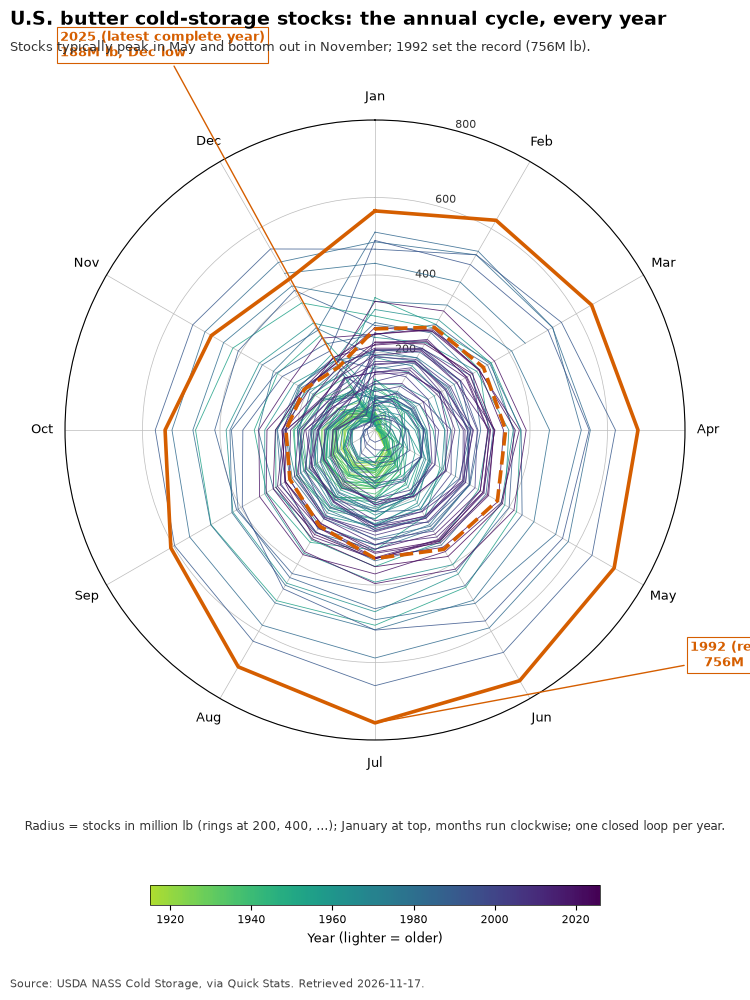

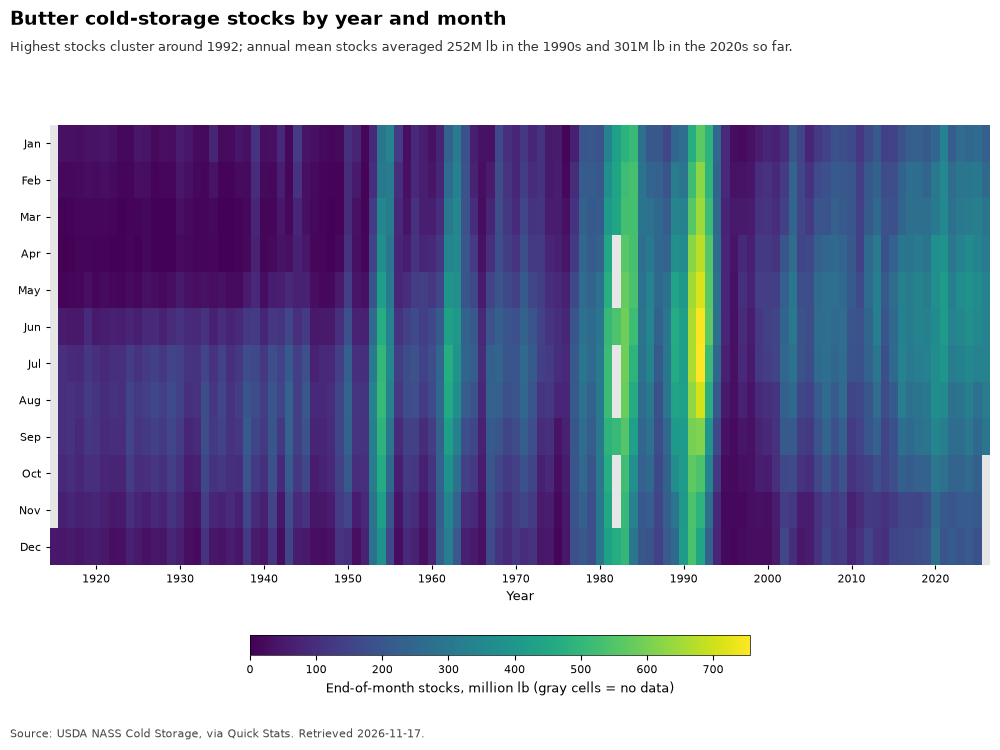

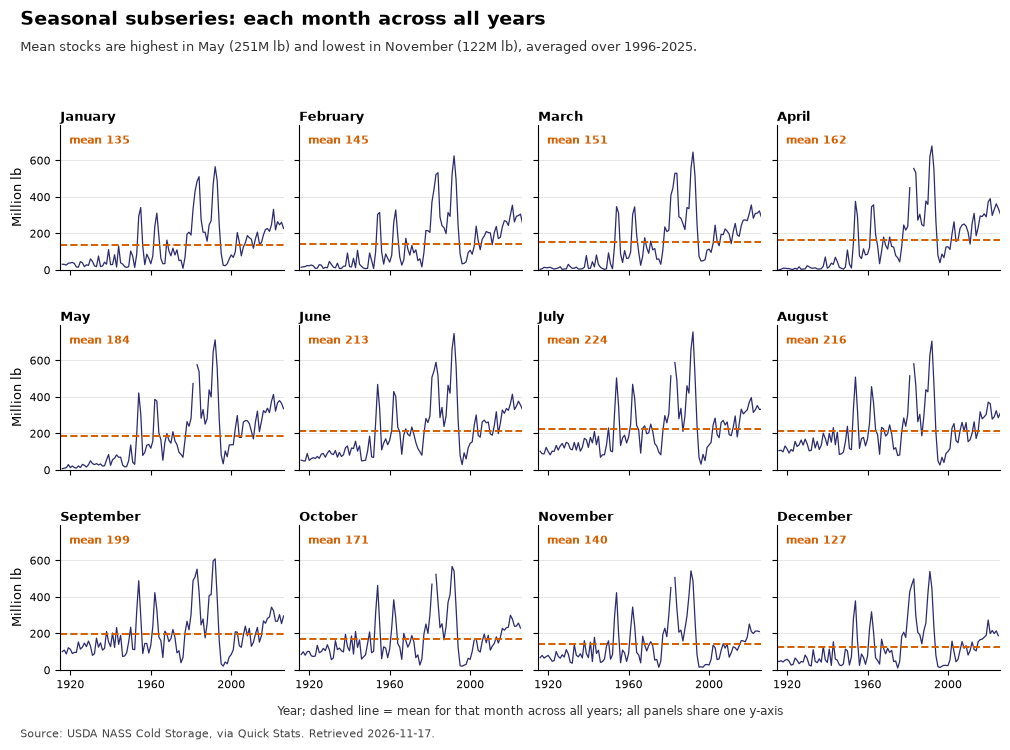

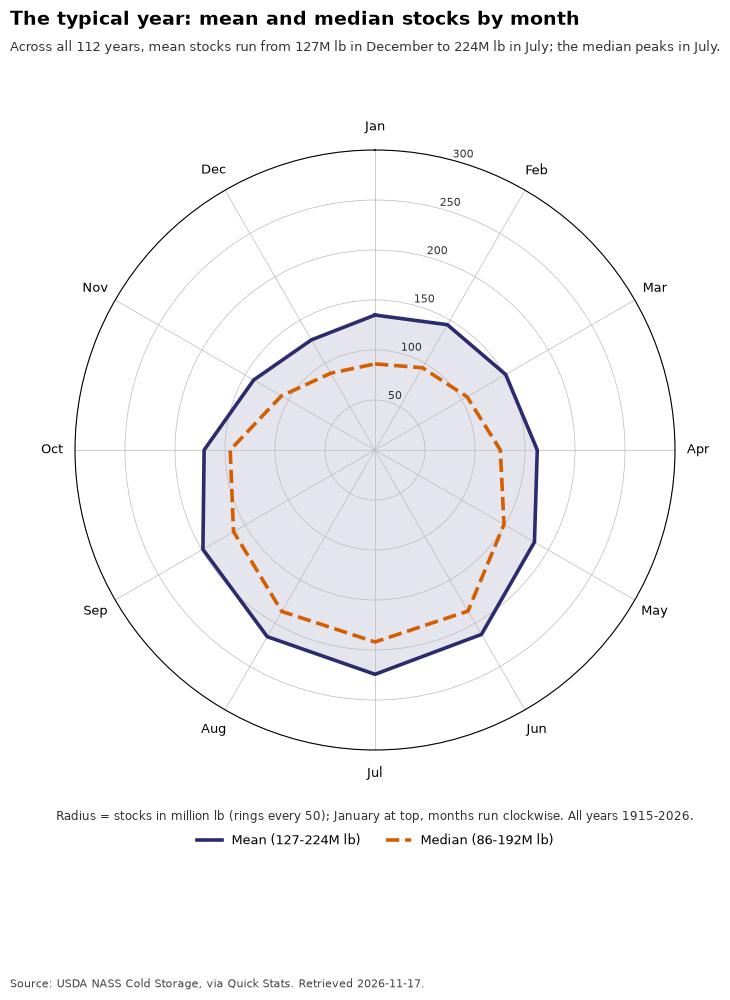

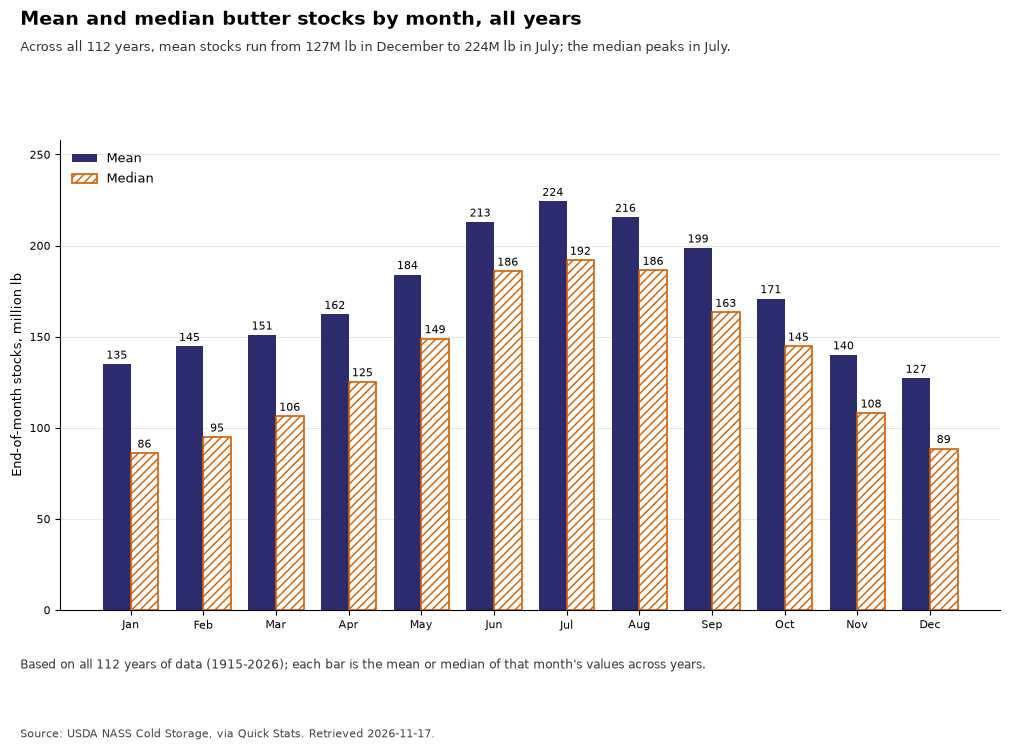

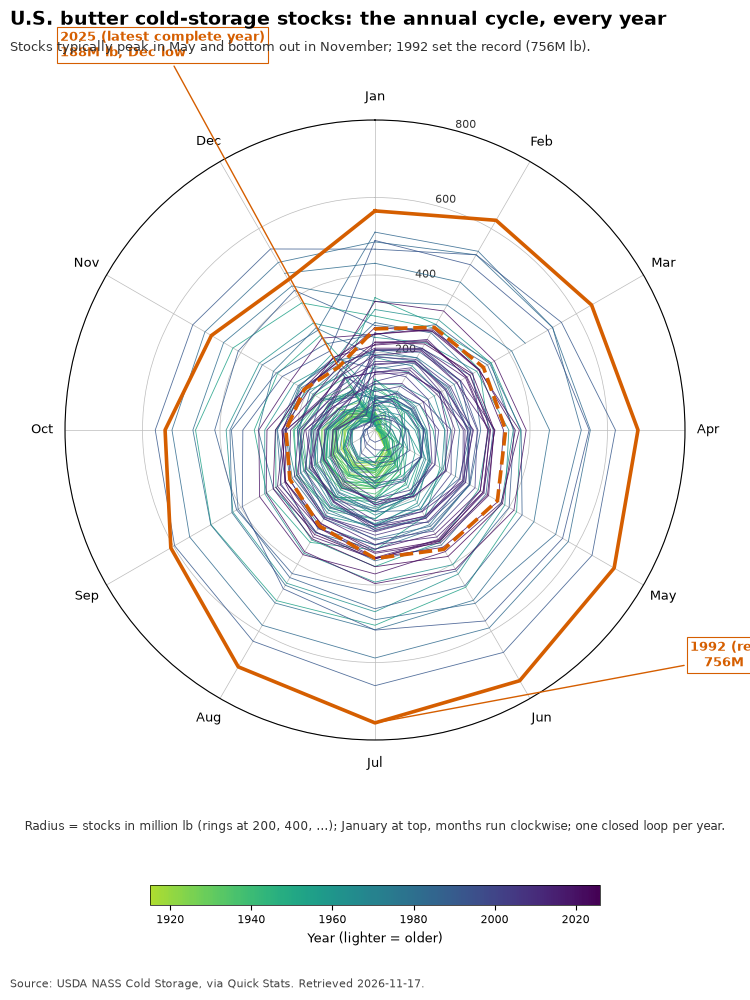

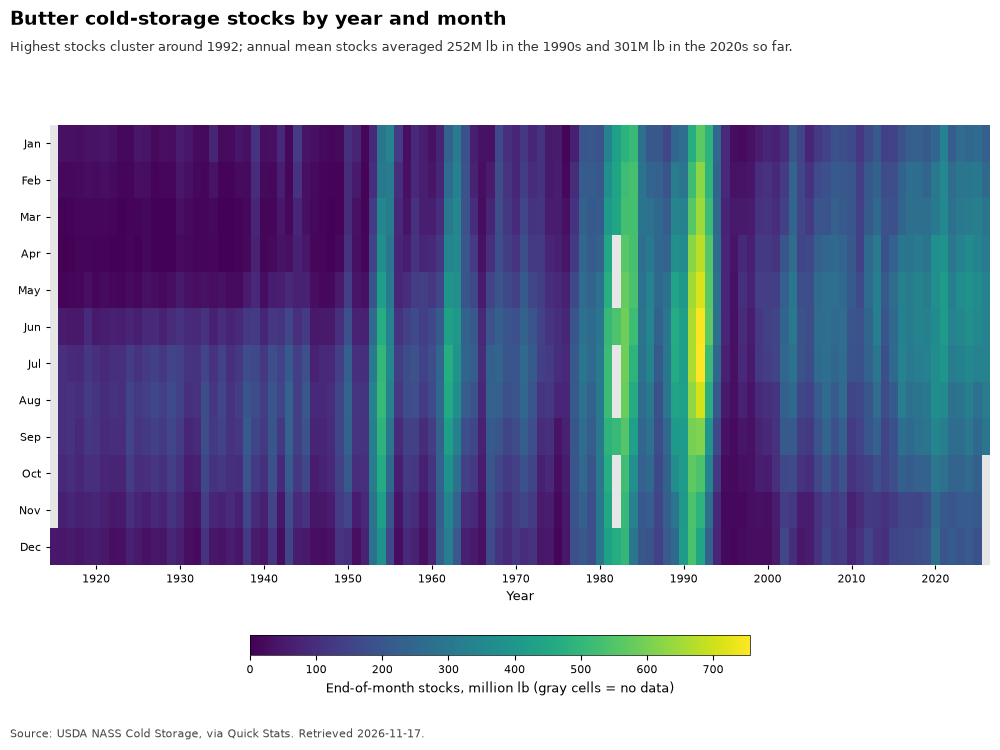

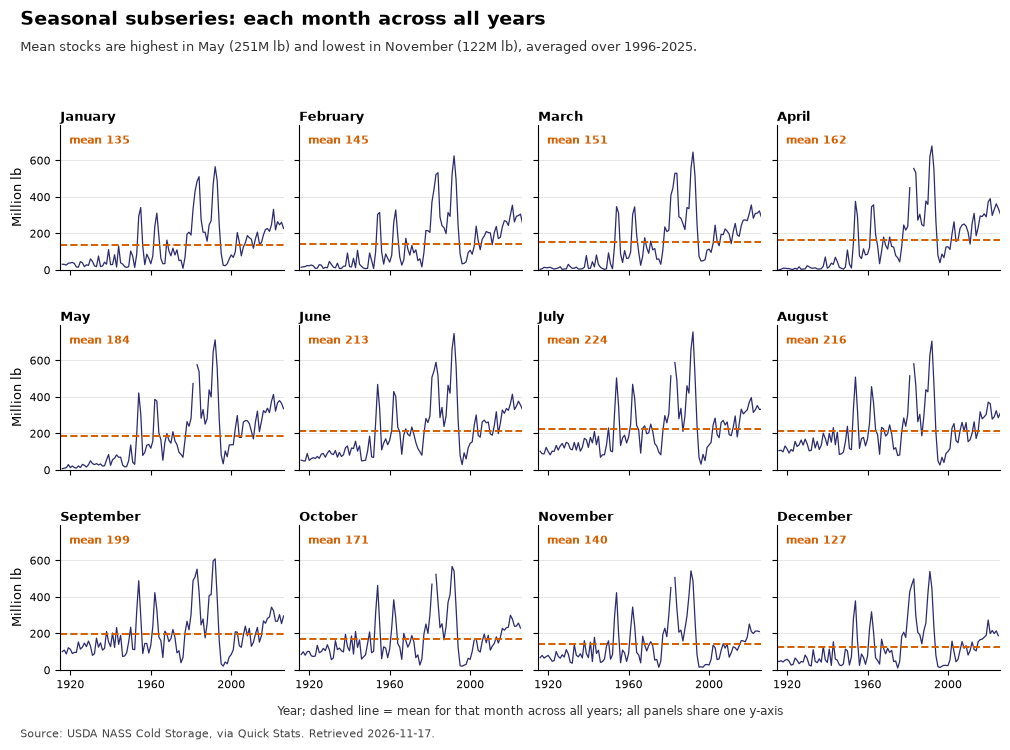

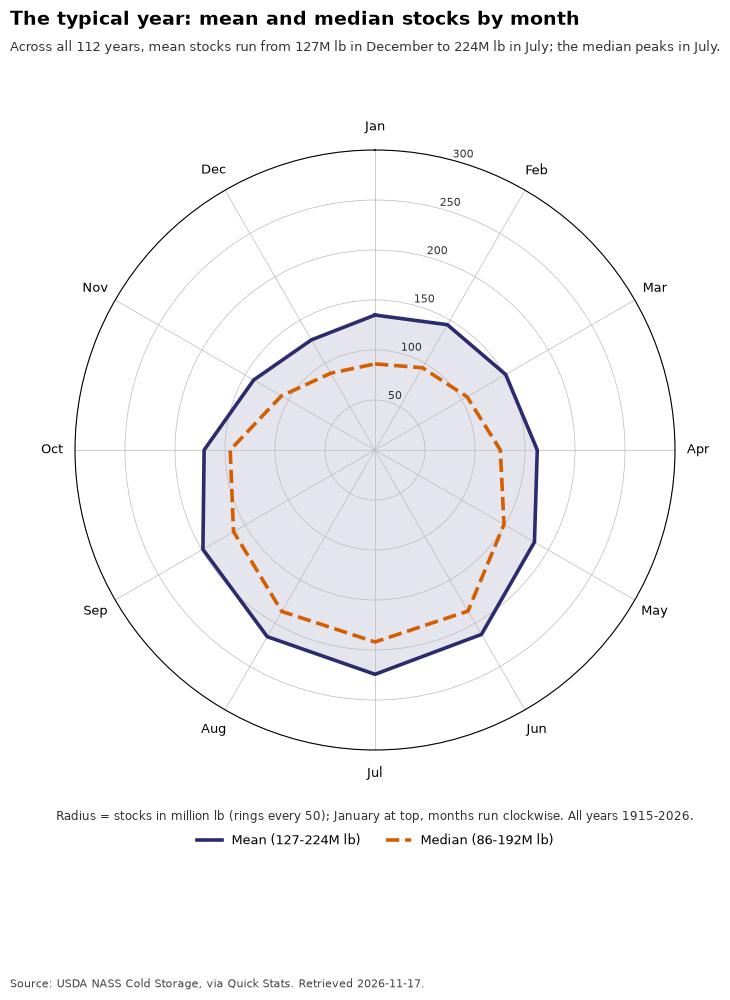

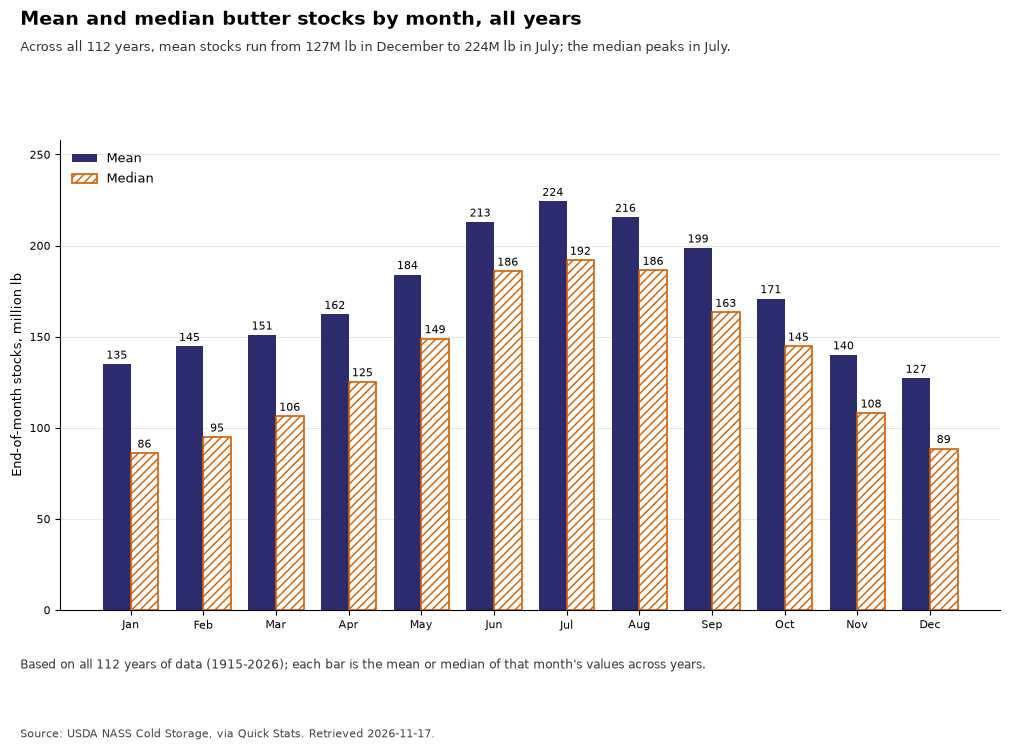

In [6]:
FOOTER = f"Source: USDA NASS Cold Storage, via Quick Stats. Retrieved {RETRIEVED}."
M = 0.6                                  # page margin, inches
HI = "#D55E00"                           # highlight colour (also distinguished by weight/style/labels)
YEARS = piv.index.values
CM = ListedColormap(plt.cm.viridis_r(np.linspace(0.12, 1.0, 256)))   # older = lighter, newer = darker
NORM = Normalize(YEARS.min(), YEARS.max())
mon_lbl = [m.title() for m in MONTHS]
FULL = dict(zip(mon_lbl, ["January","February","March","April","May","June","July","August","September","October","November","December"]))

def page(w, h, title, subtitle):
    fig = plt.figure(figsize=(w, h))
    fig.text(M/w, 1 - M/h, title, fontsize=14, fontweight="bold", va="top", ha="left")
    fig.text(M/w, 1 - (M + 0.30)/h, subtitle, fontsize=9.5, va="top", ha="left", color="#333333")
    fig.text(M/w, M/h, FOOTER, fontsize=8, va="bottom", ha="left", color="#444444")
    return fig

def inax(fig, l, b, w, h, **kw):          # axes placed by inches from the bottom-left of the page
    W, H = fig.get_size_inches()
    return fig.add_axes([l/W, b/H, w/W, h/H], **kw)

# ---------- 1. radial cycle plot (portrait) ----------
def radial():
    W, H = 8.5, 11
    sub = f"Stocks typically peak in {FULL[pk_m]} and bottom out in {FULL[tr_m]}; {RECORD_YEAR} set the record ({peak:.0f}M lb)."
    fig = page(W, H, "U.S. butter cold-storage stocks: the annual cycle, every year", sub)
    D = 6.2
    ax = inax(fig, (W - D)/2, 3.1, D, D, projection="polar")
    ax.set_theta_zero_location("N"); ax.set_theta_direction(-1)
    th = np.deg2rad(np.arange(0, 361, 30))                        # 13 points: Dec wraps back to Jan
    for y in YEARS:
        v = piv.loc[y].values
        if y in (RECORD_YEAR, LATEST_YEAR): continue
        ax.plot(th, np.r_[v, v[0]], color=CM(NORM(y)), lw=0.6, alpha=0.85)
    for y, ls in ((RECORD_YEAR, "-"), (LATEST_YEAR, "--")):
        v = piv.loc[y].values
        ax.plot(th, np.r_[v, v[0]], color=HI, lw=2.6, ls=ls, zorder=5)
    ax.set_xticks(th[:-1]); ax.set_xticklabels(mon_lbl, fontsize=9)
    ax.tick_params(axis="x", pad=6)
    top = int(np.ceil(np.nanmax(piv.values) / 200) * 200)
    ax.set_ylim(0, top); ax.set_yticks(range(200, top + 1, 200))
    ax.set_yticklabels([f"{t}" for t in range(200, top + 1, 200)], fontsize=8, color="#333333")
    ax.set_rlabel_position(15)
    ax.grid(color="#bbbbbb", lw=0.5)
    # direct labels
    rv = piv.loc[RECORD_YEAR]; m_rec = int(np.nanargmax(rv.values))
    ax.annotate(f"{RECORD_YEAR} (record)\n{rv.iloc[m_rec]:.0f}M lb, {mon_lbl[m_rec]}", xy=(th[m_rec], rv.iloc[m_rec]),
                xytext=((W - M)/W, 3.45/H), textcoords="figure fraction", fontsize=9, fontweight="bold", color=HI,
                ha="right", va="center", arrowprops=dict(arrowstyle="-", color=HI, lw=1),
                bbox=dict(fc="white", ec=HI, lw=0.8, pad=2), zorder=10)
    m_lat = int(np.nanargmin(lat.values))
    ax.annotate(f"{LATEST_YEAR} (latest complete year)\n{lat.iloc[m_lat]:.0f}M lb, {mon_lbl[m_lat]} low", xy=(th[m_lat], lat.iloc[m_lat]),
                xytext=(M/W, 9.55/H), textcoords="figure fraction", fontsize=9, fontweight="bold", color=HI,
                ha="left", va="center", arrowprops=dict(arrowstyle="-", color=HI, lw=1),
                bbox=dict(fc="white", ec=HI, lw=0.8, pad=2), zorder=10)
    fig.text(0.5, 2.3/H, "Radius = stocks in million lb (rings at 200, 400, ...); January at top, months run clockwise; one closed loop per year.",
             ha="center", va="top", fontsize=8.5, color="#333333")
    cax = inax(fig, 2.0, 1.45, 4.5, 0.2)
    cb = fig.colorbar(ScalarMappable(NORM, CM), cax=cax, orientation="horizontal")
    cb.set_label("Year (lighter = older)", fontsize=9); cb.outline.set_linewidth(0.5)
    return fig

# ---------- 2. year x month heatmap (landscape) ----------
def heatmap():
    W, H = 11, 8.5
    sub = (f"Highest stocks cluster around {RECORD_YEAR}; annual mean stocks averaged {decade[1990]:.0f}M lb in the 1990s "
           f"and {decade[2020]:.0f}M lb in the 2020s so far.")
    fig = page(W, H, "Butter cold-storage stocks by year and month", sub)
    ax = inax(fig, 1.0, 2.35, 9.4, 4.4)
    cmap = plt.get_cmap("viridis").copy(); cmap.set_bad("#e6e6e6")
    yr_edges = np.r_[YEARS - 0.5, YEARS[-1] + 0.5]
    Z = np.ma.masked_invalid(piv.values.T)                              # rows = months, cols = years
    mesh = ax.pcolormesh(yr_edges, np.arange(13), Z, cmap=cmap, rasterized=True, vmin=0)
    ax.set_ylim(12, 0); ax.set_xlim(yr_edges[0], yr_edges[-1])
    ax.set_yticks(np.arange(12) + 0.5); ax.set_yticklabels(mon_lbl)
    ax.set_xticks(np.arange(1920, YEARS.max() + 1, 10)); ax.set_xlabel("Year")
    ax.tick_params(length=3)
    for sp in ax.spines.values(): sp.set_visible(False)
    cax = inax(fig, 3.0, 1.45, 5.0, 0.2)
    cb = fig.colorbar(mesh, cax=cax, orientation="horizontal")
    cb.set_label("End-of-month stocks, million lb (gray cells = no data)", fontsize=9); cb.outline.set_linewidth(0.5)
    return fig

# ---------- 3. seasonal subseries (landscape) ----------
def subseries():
    W, H = 11, 8.5
    sub = f"Mean stocks are highest in {FULL[pk_m]} ({prof[pk_m]:.0f}M lb) and lowest in {FULL[tr_m]} ({prof[tr_m]:.0f}M lb), averaged over {RECENT[0]}-{RECENT[-1]}."
    fig = page(W, H, "Seasonal subseries: each month across all years", sub)
    gs = fig.add_gridspec(3, 4, left=1.0/W, right=10.4/W, bottom=1.3/H, top=6.75/H, hspace=0.38, wspace=0.07)
    ymax = np.nanmax(piv.values) * 1.05
    for i, m in enumerate(mon_lbl):
        ax = fig.add_subplot(gs[i // 4, i % 4])
        ax.plot(YEARS, piv[m].values, color="#2b2b6e", lw=0.9)
        mu = piv[m].mean()
        ax.axhline(mu, color=HI, lw=1.4, ls="--")
        ax.text(0.04, 0.93, f"mean {mu:.0f}", transform=ax.transAxes, fontsize=8, color=HI, fontweight="bold", va="top",
                bbox=dict(fc="white", ec="none", pad=1))
        ax.set_ylim(0, ymax); ax.set_xlim(YEARS.min(), YEARS.max())
        ax.set_title(FULL[m], fontsize=9, fontweight="bold", loc="left", pad=3)
        ax.set_xticks([1920, 1960, 2000]); ax.grid(axis="y", color="#dddddd", lw=0.5)
        if i % 4: ax.tick_params(labelleft=False)
        else: ax.set_ylabel("Million lb")
        if i < 8: ax.tick_params(labelbottom=False)
    fig.text(5.7/W, 0.85/H, "Year; dashed line = mean for that month across all years; all panels share one y-axis", ha="center", fontsize=8.5, color="#333333")
    return fig


# ---------- 4. radial: typical year (mean and median across ALL years) ----------
amean, amed = piv.mean(), piv.median()
a_pk, a_tr = amean.idxmax(), amean.idxmin()
a_sub = (f"Across all {n_years} years, mean stocks run from {amean[a_tr]:.0f}M lb in {FULL[a_tr]} to {amean[a_pk]:.0f}M lb in {FULL[a_pk]}; "
         f"the median peaks in {FULL[amed.idxmax()]}.")

def radial_typical():
    W, H = 8.5, 11
    fig = page(W, H, "The typical year: mean and median stocks by month", a_sub)
    D = 6.0
    ax = inax(fig, (W - D)/2, 3.0, D, D, projection="polar")
    ax.set_theta_zero_location("N"); ax.set_theta_direction(-1)
    th = np.deg2rad(np.arange(0, 361, 30))
    mv, dv = np.r_[amean.values, amean.values[0]], np.r_[amed.values, amed.values[0]]
    ax.fill(th, mv, color="#2b2b6e", alpha=0.12)
    ax.plot(th, mv, color="#2b2b6e", lw=2.6, label=f"Mean ({amean.min():.0f}-{amean.max():.0f}M lb)")
    ax.plot(th, dv, color=HI, lw=2.6, ls="--", label=f"Median ({amed.min():.0f}-{amed.max():.0f}M lb)")
    ax.set_xticks(th[:-1]); ax.set_xticklabels(mon_lbl, fontsize=9); ax.tick_params(axis="x", pad=6)
    top = int(np.ceil(max(amean.max(), amed.max()) / 50) * 50) + 50
    ax.set_ylim(0, top); ax.set_yticks(range(50, top + 1, 50)); ax.set_rlabel_position(15)
    ax.set_yticklabels([str(v) for v in range(50, top + 1, 50)], fontsize=8, color="#333333")
    ax.grid(color="#bbbbbb", lw=0.5)
    fig.text(0.5, 2.4/H, f"Radius = stocks in million lb (rings every 50); January at top, months run clockwise. All years {YEARS.min()}-{YEARS.max()}.",
             ha="center", va="top", fontsize=8.5, color="#333333")
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=2, frameon=False, fontsize=9)
    return fig

# ---------- 5. bar chart (landscape): mean and median by month ----------
def bars():
    W, H = 11, 8.5
    fig = page(W, H, "Mean and median butter stocks by month, all years", a_sub)
    ax = inax(fig, 1.0, 1.9, 9.4, 4.7)
    x = np.arange(12); w = 0.38
    b1 = ax.bar(x - w/2, amean.values, w, color="#2b2b6e", label="Mean")
    b2 = ax.bar(x + w/2, amed.values, w, color="white", edgecolor=HI, hatch="////", lw=1.2, label="Median")
    for bars_ in (b1, b2):
        ax.bar_label(bars_, fmt="%.0f", fontsize=8, padding=2)
    ax.set_xticks(x); ax.set_xticklabels(mon_lbl)
    ax.set_ylabel("End-of-month stocks, million lb"); ax.set_ylim(0, max(amean.max(), amed.max()) * 1.15)
    ax.grid(axis="y", color="#dddddd", lw=0.5); ax.set_axisbelow(True)
    ax.legend(loc="upper left", frameon=False, fontsize=9)
    fig.text(M/W, 1.35/H, f"Based on all {n_years} years of data ({YEARS.min()}-{YEARS.max()}); each bar is the mean or median of that month's values across years.",
             fontsize=8.5, color="#333333", va="center")
    return fig

figs = {"01_radial_cycle": radial(), "02_heatmap": heatmap(), "03_subseries": subseries(), "04_radial_typical_year": radial_typical(), "05_bar_typical_year": bars()}
for f in figs.values():
    display(f)

## 7. What the data shows
Bullets are computed from the data above (and reused on the PDF cover).

In [7]:
def trend_word(a, b): return "fell" if b < a else "rose"
rng = f"{s.dropna().index[0]:%b %Y} to {last_pt:%b %Y}"
bullets = [
    f"Coverage: {len(s.dropna())} month-end observations across {n_years} years ({rng}); {len(missing)} calendar months have no published value.",
    f"Record: {peak:.1f}M lb in {peak_date:%B %Y}. The most recent value ({last_pt:%b %Y}) is {last_val:.1f}M lb, {100 * (1 - last_val / peak):.0f}% below that peak.",
    f"Seasonality ({RECENT[0]}-{RECENT[-1]}): stocks average {prof[tr_m]:.0f}M lb in {FULL[tr_m]} and {prof[pk_m]:.0f}M lb in {FULL[pk_m]}; "
    f"the yearly high lands most often in {mon_pk.index[0]} ({mon_pk.iloc[0]} of {len(RECENT)} years) and the low in {mon_tr.index[0]} ({mon_tr.iloc[0]} of {len(RECENT)}).",
    f"Size of the cycle: the typical in-year swing from low to high is {swing:.0f}M lb over {RECENT[0]}-{RECENT[-1]}.",
    f"Level: average stocks {trend_word(decade[1990], decade[2020])} from {decade[1990]:.0f}M lb (1990s) to {decade[2020]:.0f}M lb (2020s so far); the 2010s averaged {decade[2010]:.0f}M lb.",
]
display(Markdown("\n".join("- " + b for b in bullets)))

- Coverage: 1324 month-end observations across 112 years (Dec 1915 to Sep 2026); 6 calendar months have no published value.
- Record: 755.8M lb in July 1992. The most recent value (Sep 2026) is 295.7M lb, 61% below that peak.
- Seasonality (1996-2025): stocks average 122M lb in November and 251M lb in May; the yearly high lands most often in May (15 of 30 years) and the low in Dec (15 of 30).
- Size of the cycle: the typical in-year swing from low to high is 138M lb over 1996-2025.
- Level: average stocks rose from 252M lb (1990s) to 301M lb (2020s so far); the 2010s averaged 215M lb.

## 8. PDF export
One multi-page PDF (cover + five charts, US Letter; landscape for heatmap, subseries and bars) plus one PDF per chart. Fonts are embedded as TrueType (fonttype 42); lines and text are vector, only the heatmap cells are rasterized.

In [8]:
def cover():
    W, H = 8.5, 11
    fig = page(W, H, "U.S. butter cold-storage stocks", f"Seasonal cycle across years, {rng} (million lb)")
    fig.text(M/W, 1 - 1.55/H, "Summary: what the data shows", fontsize=12, fontweight="bold", va="top")
    y = 1 - 2.0/H
    for b in bullets:
        lines = textwrap.wrap(b, 82)
        fig.text(M/W, y, "\u2022", fontsize=11, va="top")
        for k, ln in enumerate(lines):
            fig.text((M + 0.25)/W, y - k*0.215/H, ln, fontsize=10.5, va="top")
        y -= (len(lines) * 0.215 + 0.3) / H
    fig.text(M/W, y - 0.2/H, "Contents:  1 Radial cycle   2 Heatmap   3 Seasonal subseries   4 Radial typical year   5 Typical-year bars", fontsize=9.5, va="top", color="#333333")
    fig.text(M/W, y - 0.5/H, f"Series: {meta['selected_short_desc']} (USDA NASS Quick Stats, national total, end-of-month).", fontsize=8.5, va="top", color="#333333")
    return fig

cov = cover()
OUT = FIGS / "butter_cold_storage.pdf"
with PdfPages(OUT, metadata={"Title": "U.S. butter cold-storage stocks", "Author": "USDA NASS data via Quick Stats"}) as pdf:
    pdf.savefig(cov)
    for name, f in figs.items():
        pdf.savefig(f)
        f.savefig(FIGS / f"{name}.pdf")
print("wrote", OUT, "and", [f"{n}.pdf" for n in figs])

wrote figures/butter_cold_storage.pdf and ['01_radial_cycle.pdf', '02_heatmap.pdf', '03_subseries.pdf', '04_radial_typical_year.pdf', '05_bar_typical_year.pdf']


<Figure size 850x1100 with 0 Axes>